# Q3 — ZIP-market prices and household income

**Research question:** Do higher-income ZIP markets have higher DDR5 and NVMe prices?

This analysis compares location-specific prices after matching the same recorded product title and observation date across ZIP markets. The team confirmed that the geography represents location-specific prices. Exact product titles are not guaranteed to identify unique SKUs, so interpret the adjustment as controlling for recorded title and date, not perfect product identity.

Income is the 2024 ACS 5-year median household income estimate (2020–2024) for the corresponding ZIP Code Tabulation Area (ZCTA). ZCTAs approximate, but are not identical to, USPS ZIP Codes. The estimate's published margin of error (MOE) is retained. The ACS data are retrieved from the Census Reporter API, which serves Census ACS estimates. Sources: [B19013 metadata](https://api.census.gov/data/2024/acs/acs5/groups/B19013.html), [Census Reporter API](https://api.censusreporter.org/).

There are only 12 ZIP markets. The analysis is descriptive and cannot establish causation; the many product-date observations do not increase the number of independent income observations.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks/ directory")
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy.stats import linregress, pearsonr, spearmanr, t

from src.cleaning import RowLog, add_flags
from src.io import load_raw

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Load and filter the raw observations

Keep unresolved-capacity rows because this question uses listed price, not price per GB/TB. Exclude only the 17 flagged complete-system rows that are not individual components. All filtering is explicit and row counts are logged.

In [2]:
log = RowLog()
raw = load_raw(columns=[
    "series_id", "geography_id", "observed_date", "product_name",
    "quantity_value", "quantity_unit", "price_amount",
], validate=False)
df = log.note(raw, "load raw CSV", reason="Retain source observations; Q3 uses listed price")
df = add_flags(df)
df = log.note(df, "add cleaning flags", reason="Add category, unresolved-capacity, system-noise, and unit-price flags")
q3 = log.step(
    df,
    "exclude complete-system rows",
    lambda frame: frame.loc[~frame["is_system_noise"]].copy(),
    reason="DDR5 laptop/desktop/mini-PC listings are not individual components",
)

display(log.table())
print("Rows retained with unresolved capacity:", int(q3["is_unresolved"].sum()))
print("ZIP markets:", q3["geography_id"].nunique(), "| dates:", q3["observed_date"].nunique())

[load raw CSV] 127,843 -> 127,843 rows (removed 0)
[add cleaning flags] 127,843 -> 127,843 rows (removed 0)
[exclude complete-system rows] 127,843 -> 127,826 rows (removed 17)


,step,rows_before,rows_after,rows_removed,reason
0,load raw CSV,127843,127843,0,Retain source observations; Q3 uses listed price
1,add cleaning flags,127843,127843,0,"Add category, unresolved-capacity, system-nois..."
2,exclude complete-system rows,127843,127826,17,DDR5 laptop/desktop/mini-PC listings are not i...


Rows retained with unresolved capacity: 4340
ZIP markets: 12 | dates: 29


## 2. Retrieve ACS median household income

B19013 is the direct ACS table for median household income. The API response contains the estimate and its MOE for each ZCTA. ZIP codes are strings so leading zeros are preserved.

In [3]:
zip_codes = sorted(q3["geography_id"].astype("string").unique().tolist())
acs_url = "https://api.censusreporter.org/1.0/data/show/acs2024_5yr"
response = requests.get(
    acs_url,
    params={
        "table_ids": "B19013",
        "geo_ids": ",".join(f"86000US{zip_code}" for zip_code in zip_codes),
    },
    headers={"User-Agent": "DDR5-NVMe-Prices-Analysis/1.0 (academic research)"},
    timeout=30,
)
response.raise_for_status()
acs = response.json()

income_rows = []
for zip_code in zip_codes:
    geography = f"86000US{zip_code}"
    table = acs["data"][geography]["B19013"]
    income_rows.append({
        "geography_id": zip_code,
        "median_household_income": table["estimate"]["B19013001"],
        "income_moe": table["error"]["B19013001"],
    })

income = pd.DataFrame(income_rows)
assert income["geography_id"].nunique() == len(zip_codes)
assert set(income["geography_id"]) == set(zip_codes)
print("ACS release:", acs["release"]["name"], f"({acs['release']['years']})")
print("Income measure: B19013 median household income; dollars are 2024 inflation-adjusted dollars")
display(income.sort_values("median_household_income").reset_index(drop=True))

ACS release: ACS 2024 5-year (2020-2024)
Income measure: B19013 median household income; dollars are 2024 inflation-adjusted dollars


,geography_id,median_household_income,income_moe
0,62201,27437.0,22823.0
1,39206,42686.0,4731.0
2,78228,52976.0,3572.0
3,32210,61050.0,2760.0
4,77004,71199.0,9575.0
5,19145,71965.0,4229.0
6,90019,73934.0,5263.0
7,11385,88838.0,4663.0
8,60618,106384.0,3959.0
9,98118,113762.0,9666.0


## 3. Build product/date-adjusted ZIP price indices

First take the median price in each category × recorded title × date × ZIP cell. Retain product/date groups observed in at least two ZIPs. For each retained group, divide each ZIP price by the median across the observed ZIPs. The ZIP summary is the geometric mean of these relative prices (the mean log ratio), expressed as a percent from parity. This avoids a median-tie issue because most matched prices are exactly equal. Each matched product-date cell receives equal weight; DDR5 and NVMe are analyzed separately.

In [4]:
match_keys = ["series_id", "product_name", "observed_date"]
zip_cells = (
    q3.groupby(match_keys + ["geography_id"], observed=True, dropna=False)
    .agg(price=("price_amount", "median"), n_rows=("price_amount", "size"))
    .reset_index()
)
zip_cells["n_zip"] = zip_cells.groupby(match_keys, observed=True)["geography_id"].transform("nunique")
matched = zip_cells.loc[zip_cells["n_zip"] >= 2].copy()
matched["cell_median"] = matched.groupby(match_keys, observed=True)["price"].transform("median")
matched["log_relative_price"] = np.log(matched["price"] / matched["cell_median"])

coverage = (
    matched.groupby("series_id", observed=True)
    .agg(matched_zip_cells=("price", "size"),
         matched_product_dates=("product_name", lambda values: matched.loc[values.index, match_keys].drop_duplicates().shape[0]))
)
display(coverage)

def summarize_zip_prices(observations, value_col="log_relative_price", min_zip_count=2):
    """Summarize matched relative prices per category and ZIP."""
    selected = observations.loc[observations["n_zip"] >= min_zip_count]
    summary = (
        selected.groupby(["series_id", "geography_id"], observed=True)
        .agg(n_product_date_cells=(value_col, "size"), mean_log_relative=(value_col, "mean"))
        .reset_index()
    )
    summary["relative_price_pct"] = 100 * np.expm1(summary["mean_log_relative"])
    summary["relative_price_bp"] = 100 * summary["relative_price_pct"]
    return summary.merge(income, on="geography_id", validate="many_to_one")

zip_summary = summarize_zip_prices(matched)
display(zip_summary.sort_values(["series_id", "geography_id"]).reset_index(drop=True))

,matched_zip_cells,matched_product_dates
series_id,,
ddr5_memory,18261,2108
nvme_ssd,107480,12273


,series_id,geography_id,n_product_date_cells,mean_log_relative,relative_price_pct,relative_price_bp,median_household_income,income_moe
0,ddr5_memory,11385,1503,0.000071,0.007062,0.706247,88838.0,4663.0
1,ddr5_memory,19145,1536,0.000043,0.004288,0.428801,71965.0,4229.0
2,ddr5_memory,32210,1470,-0.000190,-0.018968,-1.896818,61050.0,2760.0
3,ddr5_memory,39206,1535,0.000071,0.007150,0.714982,42686.0,4731.0
4,ddr5_memory,60618,1533,-0.000117,-0.011718,-1.171836,106384.0,3959.0
5,ddr5_memory,62201,1543,0.000099,0.009862,0.986201,27437.0,22823.0
6,ddr5_memory,63105,1547,-0.000075,-0.007527,-0.752738,116439.0,13478.0
7,ddr5_memory,77004,1533,-0.000347,-0.034727,-3.472723,71199.0,9575.0
8,ddr5_memory,78228,1552,-0.000457,-0.045662,-4.566193,52976.0,3572.0
9,ddr5_memory,90019,1482,0.000092,0.009169,0.916851,73934.0,5263.0


## 4. Association and sensitivity

Pearson correlation describes a linear association; Spearman correlation checks whether the rank association agrees. The slope is an effect size: change in relative price index (percentage points) per $10,000 higher median income. A conventional 95% t-based interval is reported for that slope. Leave-one-ZIP-out ranges and stricter product/date overlap checks show how sensitive the result is to individual markets and sparse matches. These calculations use ZIP markets as the observations (n=12), not raw listing rows.

In [5]:
def association_results(summary):
    rows = []
    for category, group in summary.groupby("series_id", observed=True):
        x = group["median_household_income"].to_numpy(dtype=float)
        y = group["relative_price_pct"].to_numpy(dtype=float)
        linear = linregress(x, y)
        critical_t = t.ppf(0.975, df=len(group) - 2)
        loo_r = []
        for index in group.index:
            left_out = group.drop(index)
            loo_r.append(pearsonr(left_out["median_household_income"], left_out["relative_price_pct"]).statistic)
        rows.append({
            "category": category,
            "n_zip": len(group),
            "pearson_r": pearsonr(x, y).statistic,
            "pearson_p": pearsonr(x, y).pvalue,
            "spearman_rho": spearmanr(x, y).statistic,
            "spearman_p": spearmanr(x, y).pvalue,
            "slope_pct_per_10000": linear.slope * 10_000,
            "slope_ci_low": (linear.slope - critical_t * linear.stderr) * 10_000,
            "slope_ci_high": (linear.slope + critical_t * linear.stderr) * 10_000,
            "r_squared": linear.rvalue ** 2,
            "loo_pearson_min": min(loo_r),
            "loo_pearson_max": max(loo_r),
        })
    return pd.DataFrame(rows)

primary_results = association_results(zip_summary)
display(primary_results.round(5))

sensitivity_rows = []
for min_zip_count in (2, 6, 12):
    current = summarize_zip_prices(matched, min_zip_count=min_zip_count)
    result = association_results(current)
    result.insert(0, "minimum ZIPs per product-date", min_zip_count)
    sensitivity_rows.append(result)

clipped = matched.copy()
clipped["log_relative_clipped"] = clipped.groupby("series_id", observed=True)["log_relative_price"].transform(
    lambda values: values.clip(values.quantile(0.01), values.quantile(0.99))
)
clipped_summary = summarize_zip_prices(clipped, value_col="log_relative_clipped")
clipped_result = association_results(clipped_summary)
clipped_result.insert(0, "sensitivity", "clip cell log ratios at category 1st/99th percentiles")
threshold_results = pd.concat(sensitivity_rows, ignore_index=True)
threshold_results.insert(0, "sensitivity", "minimum ZIP overlap")
display(pd.concat([threshold_results, clipped_result], ignore_index=True).round(5))

,category,n_zip,pearson_r,pearson_p,spearman_rho,spearman_p,slope_pct_per_10000,slope_ci_low,slope_ci_high,r_squared,loo_pearson_min,loo_pearson_max
0,ddr5_memory,12,0.31893,0.31229,0.29371,0.35415,0.00211,-0.00231,0.00652,0.10172,0.19353,0.47220
1,nvme_ssd,12,0.37327,0.23203,0.31469,0.31914,0.00217,-0.00163,0.00597,0.13933,0.21422,0.55402


,sensitivity,minimum ZIPs per product-date,category,n_zip,pearson_r,pearson_p,spearman_rho,spearman_p,slope_pct_per_10000,slope_ci_low,slope_ci_high,r_squared,loo_pearson_min,loo_pearson_max
0,minimum ZIP overlap,2.0,ddr5_memory,12,0.31893,0.31229,0.29371,0.35415,0.00211,-0.00231,0.00652,0.10172,0.19353,0.47220
1,minimum ZIP overlap,2.0,nvme_ssd,12,0.37327,0.23203,0.31469,0.31914,0.00217,-0.00163,0.00597,0.13933,0.21422,0.55402
2,minimum ZIP overlap,6.0,ddr5_memory,12,0.32702,0.29948,0.46154,0.13095,0.00236,-0.00245,0.00717,0.10694,0.20802,0.47009
3,minimum ZIP overlap,6.0,nvme_ssd,12,0.39500,0.20380,0.39860,0.19934,0.00251,-0.00160,0.00663,0.15602,0.24722,0.57260
4,minimum ZIP overlap,12.0,ddr5_memory,12,0.37405,0.23098,0.44755,0.14459,0.00319,-0.00238,0.00877,0.13992,0.28296,0.46384
5,minimum ZIP overlap,12.0,nvme_ssd,12,0.38966,0.21053,0.32168,0.30791,0.00370,-0.00246,0.00987,0.15184,0.22900,0.55486
6,clip cell log ratios at category 1st/99th perc...,NaN,ddr5_memory,12,0.40946,0.18623,0.46853,0.12445,0.00119,-0.00068,0.00306,0.16766,0.31192,0.55030
7,clip cell log ratios at category 1st/99th perc...,NaN,nvme_ssd,12,0.32809,0.29781,0.27273,0.39110,0.00027,-0.00028,0.00081,0.10764,0.14927,0.48401


## 5. Visualize the ZIP-level data

The first plot relates income to the adjusted price index; horizontal bars show the ACS income MOE. The second ranks ZIPs by adjusted relative price. The index is shown in basis points (1 basis point = 0.01 percentage point) because the observed differences are small. Each point/market is one ZIP.

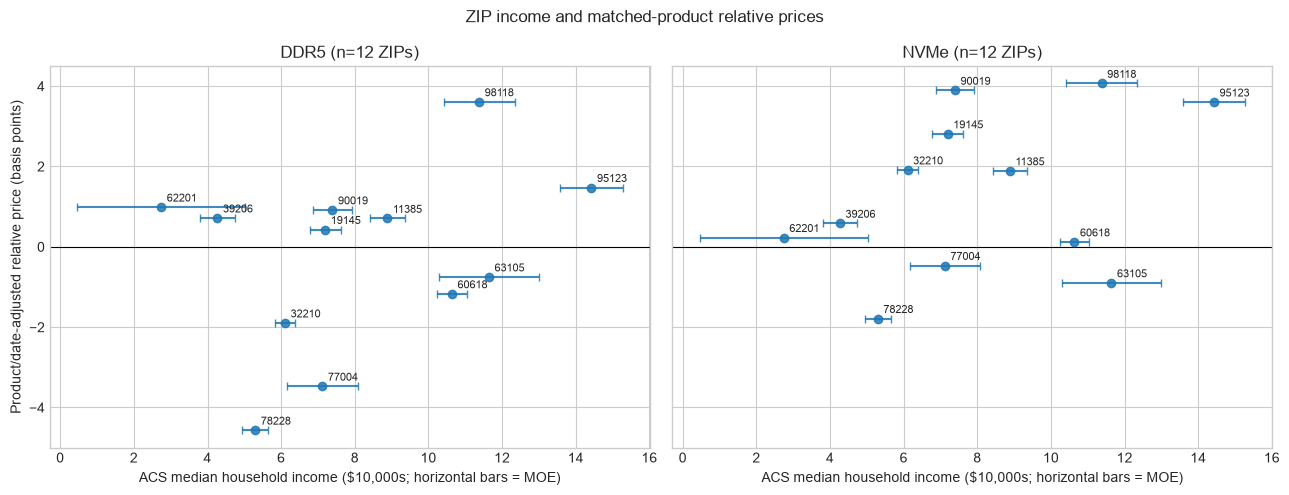

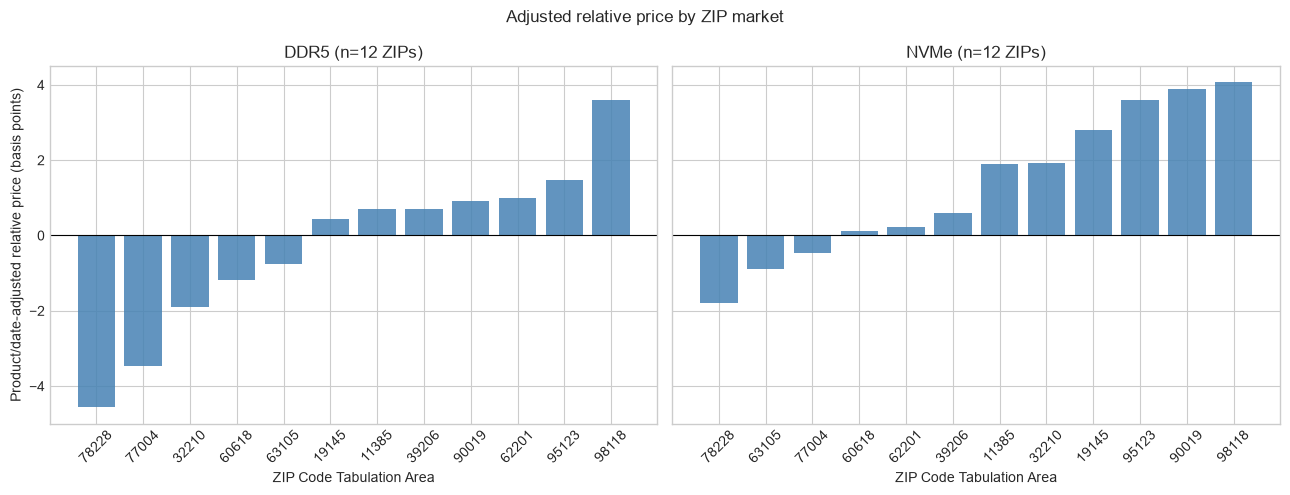

In [6]:
categories = ["ddr5_memory", "nvme_ssd"]
category_labels = {"ddr5_memory": "DDR5", "nvme_ssd": "NVMe"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, category in zip(axes, categories):
    group = zip_summary.loc[zip_summary["series_id"] == category].copy()
    ax.errorbar(
        group["median_household_income"] / 10_000,
        group["relative_price_bp"],
        xerr=group["income_moe"] / 10_000,
        fmt="o", capsize=3, alpha=0.85,
    )
    for row in group.itertuples():
        ax.annotate(row.geography_id, (row.median_household_income / 10_000, row.relative_price_bp),
                    xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{category_labels[category]} (n={len(group)} ZIPs)")
    ax.set_xlabel("ACS median household income ($10,000s; horizontal bars = MOE)")
axes[0].set_ylabel("Product/date-adjusted relative price (basis points)")
fig.suptitle("ZIP income and matched-product relative prices")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, category in zip(axes, categories):
    group = zip_summary.loc[zip_summary["series_id"] == category].sort_values("relative_price_bp")
    bars = ax.bar(group["geography_id"], group["relative_price_bp"], color="steelblue", alpha=0.85)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{category_labels[category]} (n={len(group)} ZIPs)")
    ax.set_xlabel("ZIP Code Tabulation Area")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Product/date-adjusted relative price (basis points)")
fig.suptitle("Adjusted relative price by ZIP market")
fig.tight_layout()
plt.show()

## Preliminary read-out

- The adjusted ZIP price index spans about **−0.046% to +0.036% for DDR5** and **−0.018% to +0.041% for NVMe** relative to the product/date reference. These are small market differences.
- Income correlations are positive but not statistically distinguishable from zero with 12 ZIPs: **DDR5 Pearson r=0.319 (p=0.312), Spearman ρ=0.294 (p=0.354)**; **NVMe Pearson r=0.373 (p=0.232), Spearman ρ=0.315 (p=0.319)**.
- The estimated linear slopes are only **+0.0021 and +0.0022 index percentage points per $10,000** for DDR5 and NVMe. Their 95% intervals include zero (DDR5: −0.0023 to +0.0065; NVMe: −0.0016 to +0.0060).
- The sign stays positive in the leave-one-ZIP-out checks and under the displayed overlap/clipping sensitivities, but estimates remain small and imprecise. This is **not evidence that income causes component prices to rise**; the data support only a cautious descriptive comparison.
- The plots show ACS margins of error, but the correlation and slope intervals treat income estimates as fixed and do not propagate ACS income uncertainty.

## Interpretation checklist

- Describe the association separately for DDR5 and NVMe; do not treat their prices as interchangeable.
- Report the index range and slope in practical units alongside correlations and uncertainty.
- Check whether the sign and magnitude persist under the overlap and clipping sensitivities above.
- Keep the conclusion descriptive: 12 ZIPs, ACS ZCTA-to-ZIP approximation, ACS income MOE, and short product-price collection window limit inference.
- A matched title is not proof of a unique SKU. The price adjustment is only as good as the product-title matching.